In [1]:
import Pkg

Pkg.activate(dirname(@__DIR__))
Pkg.add(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"])
Pkg.status(["DynamicalSystems", "CairoMakie", "OrdinaryDiffEq", "BenchmarkTools"]; mode = Pkg.PKGMODE_MANIFEST)
Pkg.instantiate()
Base.active_project()

  Activating project at `c:\Users\stant\OneDrive - University of Exeter\Documents\Maths`
     Project No packages added to or removed from `C:\Users\stant\OneDrive - University of Exeter\Documents\Maths\Project.toml`
    Manifest No packages added to or removed from `C:\Users\stant\OneDrive - University of Exeter\Documents\Maths\Manifest.toml`


Status `C:\Users\stant\OneDrive - University of Exeter\Documents\Maths\Manifest.toml`
  [47edcb42] ADTypes v1.24.0
  [f3fd9213] Attractors v2.0.5
  [6e4b80f9] BenchmarkTools v1.8.0
  [159f3aea] Cairo v1.1.1
  [13f3f980] CairoMakie v0.15.15
  [608a59af] ChaosTools v3.5.4
  [5ae59095] Colors v0.13.2
  [38540f10] CommonSolve v0.2.14
  [34da2185] Compat v4.18.1
  [ab4b797d] ComplexityMeasures v3.11.0
  [864edb3b] DataStructures v0.19.6
  [5732040d] DelayEmbeddings v2.9.0
  [2b5f629d] DiffEqBase v7.21.3
  [ffbed154] DocStringExtensions v0.9.5
  [61744808] DynamicalSystems v3.7.0
  [6e36e845] DynamicalSystemsBase v3.19.3
  [5789e2e9] FileIO v1.20.0
  [4665ce21] FractalDimensions v1.9.6
  [b38be410] FreeType v4.1.1
  [5c1252a2] GeometryBasics v0.5.13
  [682c06a0] JSON v1.10.0
  [ee78f7c6] Makie v0.24.15
  [1dea7af3] OrdinaryDiffEq v7.8.1
  [6ad6398a] OrdinaryDiffEqBDF v2.4.12
  [bbf590c4] OrdinaryDiffEqCore v4.18.1
  [50262376] OrdinaryDiffEqDefault v2.6.2
  [43230ef6] OrdinaryDiffEqRosenbroc

"c:\\Users\\stant\\OneDrive - University of Exeter\\Documents\\Maths\\Project.toml"

In [2]:
using DynamicalSystems
using CairoMakie
using Statistics

## Question 1

### 1.3

In [3]:
function q1(u, p, t)
    x, y, z = u
    a, b, c = p
    dx = - y - z
    dy = x + a*y
    dz = b + z*(x-c)
    return SVector(dx, dy, dz)
end

q1 (generic function with 1 method)

In [4]:
@doc scatter

```julia
scatter(positions)
scatter(x, y)
scatter(x, y, z)
```

Plots a marker for each element in `(x, y, z)`, `(x, y)`, or `positions`.

## Plot type

The plot type alias for the `scatter` function is `Scatter`.

## Attributes

**`alpha`** =  `1.0`  — The alpha value of the colormap or color attribute. Multiple alphas like in `plot(alpha=0.2, color=(:red, 0.5))`, will get multiplied.

**`clip_planes`** =  `@inherit clip_planes automatic`  — Clip planes offer a way to do clipping in 3D space. You can set a Vector of up to 8 `Plane3f` planes here, behind which plots will be clipped (i.e. become invisible). By default clip planes are inherited from the parent plot or scene. You can remove parent `clip_planes` by passing `Plane3f[]`.

**`color`** =  `@inherit markercolor`  — Sets the color of the marker. If no color is set, multiple calls to `scatter!` will cycle through the axis color palette.

**`colormap`** =  `@inherit colormap :viridis`  — Sets the colormap that is sampled for numeric `color`s. `PlotUtils.cgrad(...)`, `Makie.Reverse(any_colormap)` can be used as well, or any symbol from ColorBrewer or PlotUtils. To see all available color gradients, you can call `Makie.available_gradients()`.

**`colorrange`** =  `automatic`  — The values representing the start and end points of `colormap`.

**`colorscale`** =  `identity`  — The color transform function. Can be any function, but only works well together with `Colorbar` for `identity`, `log`, `log2`, `log10`, `sqrt`, `logit`, `Makie.pseudolog10`, `Makie.Symlog10`, `Makie.AsinhScale`, `Makie.SinhScale`, `Makie.LogScale`, `Makie.LuptonAsinhScale`, and `Makie.PowerScale`.

**`cycle`** =  `[:color]`  — Sets which attributes to cycle when creating multiple plots. The values to cycle through are defined by the parent Theme. Multiple cycled attributes can be set by passing a vector. Elements can

  * directly refer to a cycled attribute, e.g. `:color`
  * map a cycled attribute to a palette attribute, e.g. `:linecolor => :color`
  * map multiple cycled attributes to a palette attribute, e.g. `[:linecolor, :markercolor] => :color`

**`depth_shift`** =  `0.0`  — Adjusts the depth value of a plot after all other transformations, i.e. in clip space, where `-1 <= depth <= 1`. This only applies to GLMakie and WGLMakie and can be used to adjust render order (like a tunable overdraw).

**`depthsorting`** =  `false`  — Enables depth-sorting of markers which can improve border artifacts. Currently supported in GLMakie only.

**`distancefield`** =  `nothing`  — Optional distancefield used for e.g. font and bezier path rendering. Will get set automatically.

**`font`** =  `"default"`  — Sets the font to be used for character markers

**`fxaa`** =  `false`  — Adjusts whether the plot is rendered with fxaa (fast approximate anti-aliasing, GLMakie only). Note that some plots implement a better native anti-aliasing solution (scatter, text, lines). For them `fxaa = true` generally lowers quality. Plots that show smoothly interpolated data (e.g. image, surface) may also degrade in quality as `fxaa = true` can cause blurring.

**`glowcolor`** =  `(:black, 0.0)`  — Sets the color of the glow effect around the marker.

**`glowwidth`** =  `0.0`  — Sets the size of a glow effect around the marker.

**`highclip`** =  `automatic`  — The color for any value above the colorrange.

**`inspectable`** =  `@inherit inspectable`  — Sets whether this plot should be seen by `DataInspector`. The default depends on the theme of the parent scene.

**`inspector_clear`** =  `automatic`  — Sets a callback function `(inspector, plot) -> ...` for cleaning up custom indicators in DataInspector.

**`inspector_hover`** =  `automatic`  — Sets a callback function `(inspector, plot, index) -> ...` which replaces the default `show_data` methods.

**`inspector_label`** =  `automatic`  — Sets a callback function `(plot, index, position) -> string` which replaces the default label generated by DataInspector.

**`lowclip`** =  `automatic`  — The color for any value below the colorrange.

**`marker`** =  `@inherit marker`  — Sets the scatter marker.

**`marker_offset`** =  `Vec3f(0)`  — The offset of the marker from the given position in `markerspace` units. An offset of 0 corresponds to a centered marker.

**`markersize`** =  `@inherit markersize`  — Sets the size of the marker by scaling it relative to its base size which can differ for each marker. A `Real` scales x and y dimensions by the same amount. A `Vec` or `Tuple` with two elements scales x and y separately. An array of either scales each marker separately. Humans perceive the area of a marker as its size which grows quadratically with `markersize`, so multiplying `markersize` by 2 results in a marker that is 4 times as large, visually.

**`markerspace`** =  `:pixel`  — Sets the space in which `markersize` is given. See `Makie.spaces()` for possible inputs

**`model`** =  `automatic`  — Sets a model matrix for the plot. This overrides adjustments made with `translate!`, `rotate!` and `scale!`.

**`nan_color`** =  `:transparent`  — The color for NaN values.

**`overdraw`** =  `false`  — Controls if the plot will draw over other plots. This specifically means ignoring depth checks in GL backends

**`rasterize`** =  `@inherit rasterize false`  — Controls whether CairoMakie rasterizes a plot (true, >0) or not (false, 0). If an integer is given, it sets the pixel density for rasterization.

**`rotation`** =  `Billboard()`  — Sets the rotation of the marker. A `Billboard` rotation is always around the depth axis.

**`space`** =  `:data`  — Sets the transformation space for box encompassing the plot. See `Makie.spaces()` for possible inputs.

**`ssao`** =  `false`  — Adjusts whether the plot is rendered with ssao (screen space ambient occlusion). Note that this only makes sense in 3D plots and is only applicable with `fxaa = true`.

**`strokecolor`** =  `@inherit markerstrokecolor`  — Sets the color of the outline around a marker.

**`strokewidth`** =  `@inherit markerstrokewidth`  — Sets the width of the outline around a marker.

**`transform_marker`** =  `false`  — Controls whether the model matrix (without translation) applies to the marker itself, rather than just the positions. (If this is true, `scale!` and `rotate!` will affect the marker.

**`transformation`** =  `:automatic`  — Controls the inheritance or directly sets the transformations of a plot. Transformations include the transform function and model matrix as generated by `translate!(...)`, `scale!(...)` and `rotate!(...)`. They can be set directly by passing a `Transformation()` object or inherited from the parent plot or scene. Inheritance options include:

  * `:automatic`: Inherit transformations if the parent and child `space` is compatible
  * `:inherit`: Inherit transformations
  * `:inherit_model`: Inherit only model transformations
  * `:inherit_transform_func`: Inherit only the transform function
  * `:nothing`: Inherit neither, fully disconnecting the child's transformations from the parent

Another option is to pass arguments to the `transform!()` function which then get applied to the plot. For example `transformation = (:xz, 1.0)` which rotates the `xy` plane to the `xz` plane and translates by `1.0`. For this inheritance defaults to `:automatic` but can also be set through e.g. `(:nothing, (:xz, 1.0))`.

**`transparency`** =  `false`  — Adjusts how the plot deals with transparency. In GLMakie `transparency = true` results in using Order Independent Transparency.

**`visible`** =  `true`  — Controls whether the plot gets rendered or not.


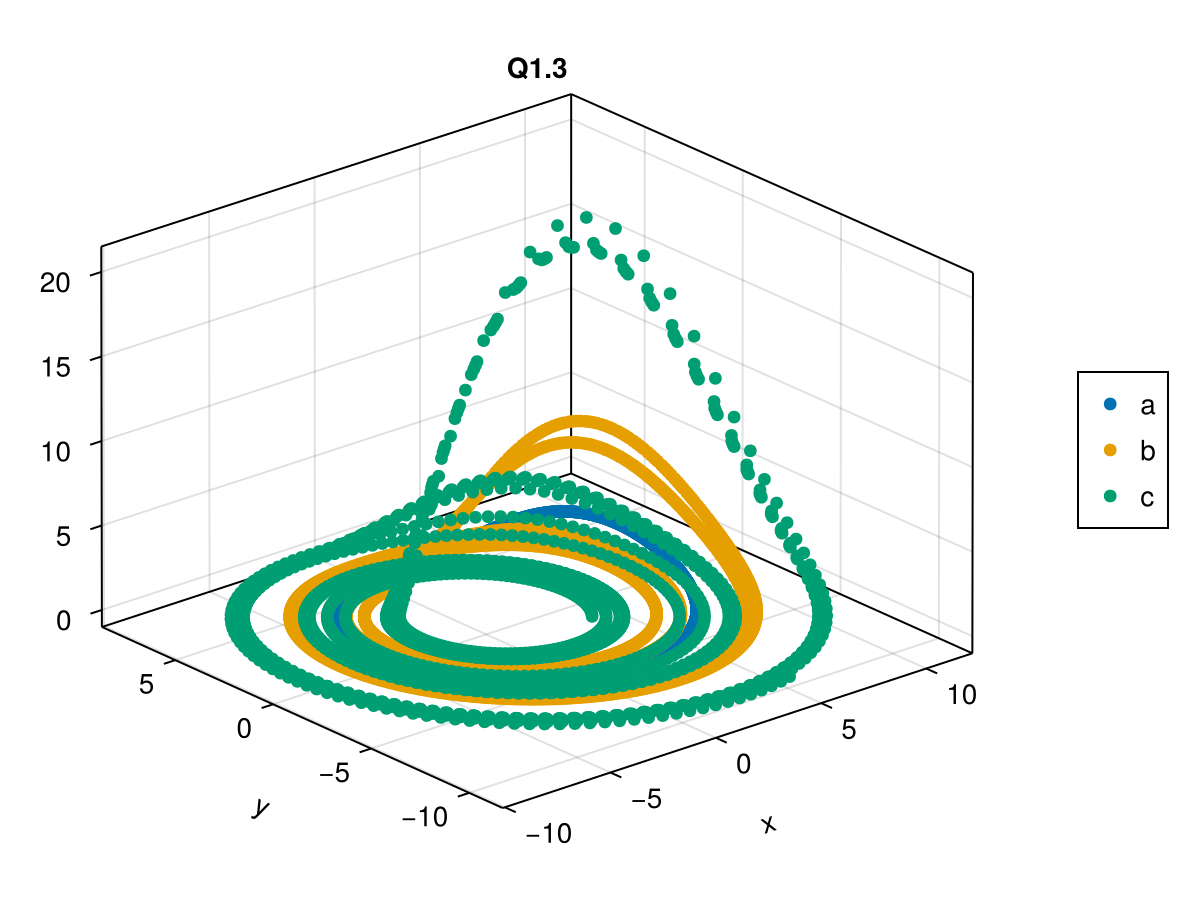

CairoMakie.Screen{IMAGE}


In [ ]:
b_vals = [1.6, 0.8, 0.2]
colours = ["red", "green", "blue"]
graphs = []

fig = Figure()
ax = Axis3(fig[1, 1]; title = "Q1.3")

for b in b_vals
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1vals = CoupledODEs(q1, u0, p0)
    total_time = 100
    X, t = trajectory(q1vals, total_time; Ttr = 1000, Δt = 0.05)
    graph = scatter!(ax, X)
    push!(graphs, graph)
end

Legend(fig[1, 2], graphs, ["a", "b", "c"])
display(fig)

### 1.4

In [6]:
mean_x_vals = []
mean_z_vals = []
b_values = []
for b in 0.2:0.01:1.6
    p0 = [0.2, b, 5.7]
    u0 = [5.2, 0, 0]
    q1_4vals = CoupledODEs(q1, u0, p0)
    total_time = 1_000
    X, t = trajectory(q1_4vals, total_time; Ttr = 1000)
    x_vals, _, z_vals = columns(X)
    mean_x = mean(x_vals)
    mean_z = mean(z_vals)
    push!(mean_x_vals, mean_x)
    push!(mean_z_vals, mean_z)
    push!(b_values, b)
end



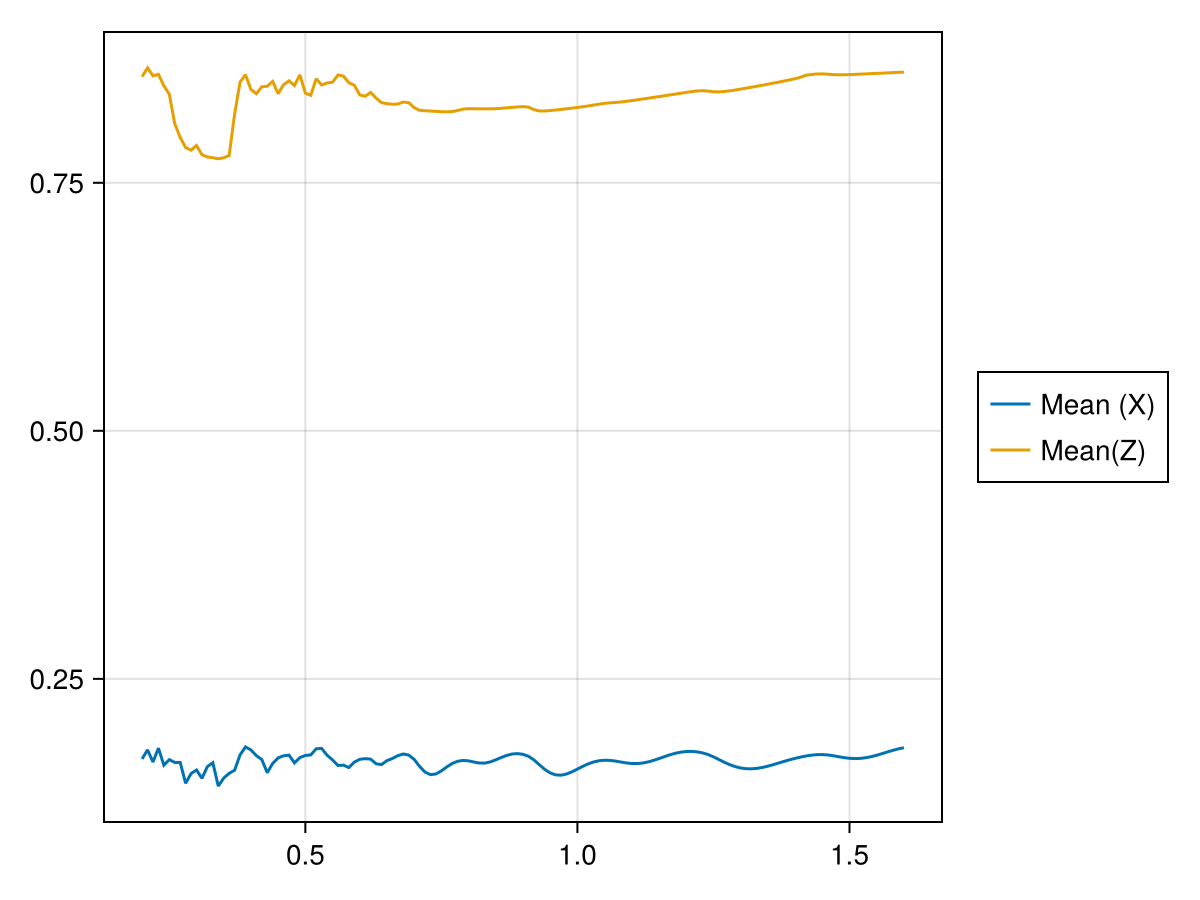

In [7]:
fig = Figure()
ax = Axis(fig[1,1])
x_graph = lines!(ax, b_values, mean_x_vals)
z_graph = lines!(ax, b_values, mean_z_vals)
Legend(fig[1, 2], [x_graph, z_graph], ["Mean (X)", "Mean(Z)"])
fig

In [8]:
function psos1(A, index, value)
    # Estimate poincare section of traj(A) with hyperplane defined for when var(traj) with given index
    # crosses a specific value (- => +)
    # Use interpolation
    pass
end

psos1 (generic function with 1 method)

In [9]:
function psos2(A, tvec, index, value)
    pass
end

psos2 (generic function with 1 method)